# Question 1: Data Ingestion, Target Derivation & Leakage Isolation
- **Dataset:** `navodPeiris/sri-lanka-case-law` from Hugging Face
- **Objective:** Ingest dataset, derive statutory domain labels from structured metadata, and perform a strict grouped split to eliminate temporal/case-level leakage.

In [1]:
import sys
!{sys.executable} -m pip install datasets scikit-learn matplotlib seaborn pandas numpy

In [2]:


import os
import json
import ast
import pandas as pd 
import numpy as np
from datasets import load_dataset
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully.")


d:\Software\Python\envs\ANN\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully.


In [3]:
import numpy as np
import ast

def extract_primary_statute(laws):
    """
    Extracts the primary governing statute/domain from the laws_referred column 
    (which Hugging Face natively parses as a list of dictionaries or elements).
    """
    if laws is None:
        return "General Appellate / Other"
        
    # Check for pandas/numpy missing values safely
    try:
        if pd.isna(laws):
            return "General Appellate / Other"
    except Exception:
        pass

    # If it's a string, try parsing it just in case
    if isinstance(laws, str):
        if not laws.strip():
            return "General Appellate / Other"
        try:
            laws = ast.literal_eval(laws)
        except Exception:
            pass

    # Handle native lists, tuples, or arrays
    law_title = ""
    if isinstance(laws, (list, tuple, np.ndarray)):
        if len(laws) == 0:
            return "General Appellate / Other"
        first_law = laws[0]
        if isinstance(first_law, dict):
            law_title = str(first_law.get('law', '') or first_law.get('title', '') or first_law.get('name', ''))
        else:
            law_title = str(first_law)
    elif isinstance(laws, dict):
        law_title = str(laws.get('law', '') or laws.get('title', '') or laws.get('name', ''))
    else:
        law_title = str(laws)

    # Map top Sri Lankan Statutes to Target Domains
    law_title_upper = law_title.upper()
    if "PENAL" in law_title_upper or "CRIMINAL" in law_title_upper:
        return "Penal Code / Criminal"
    elif "CIVIL" in law_title_upper or "REQUESTS" in law_title_upper or "PROPERTY" in law_title_upper:
        return "Civil Procedure / Property"
    elif "INDUSTRIAL" in law_title_upper or "LABOUR" in law_title_upper:
        return "Industrial & Labour Disputes"
    elif "CONSTITUTION" in law_title_upper or "FUNDAMENTAL" in law_title_upper:
        return "Constitutional & FR"
    elif "TAX" in law_title_upper or "REVENUE" in law_title_upper:
        return "Tax & Commercial"
    elif "ORDINANCE" in law_title_upper:
        return "Statutory & Administrative"
    
    return "General Appellate / Other"

print("Updated robust helper function defined successfully!")

Updated robust helper function defined successfully!


In [4]:
print("Fetching dataset strictly from Hugging Face as decided: navodPeiris/sri-lanka-case-law...")

# Load the exact official dataset specified in the proposal 
dataset = load_dataset("navodPeiris/sri-lanka-case-law")

# check availanle splits dynamically
print(f"\nAvailable dataset splits: {list(dataset.keys())}")

# Automatically select the first available split (e.g., 'train' or default)
split_key = list(dataset.keys())[0]
df = pd.DataFrame(dataset[split_key])

print(f"\nDataset loaded successfully from split '{split_key}'! Total Raw Records: {len(df)}")
print(f"Available columns: {list(df.columns)}")
df.head(2)

Fetching dataset strictly from Hugging Face as decided: navodPeiris/sri-lanka-case-law...



Available dataset splits: ['CLR', 'CLW', 'NLR', 'SLR', 'combined']

Dataset loaded successfully from split 'CLR'! Total Raw Records: 291
Available columns: ['source', 'case_no', 'court_citation', 'court', 'case_title', 'short_summary', 'full_summary', 'decided_date', 'judges', 'citations', 'laws_referred', 'arguments', 'judgements']


,source,case_no,court_citation,court,case_title,short_summary,full_summary,decided_date,judges,citations,laws_referred,arguments,judgements
0,CLR,01 CLR 001,,,Casy Lebbe Marikar vs Aydroos Lebbe Marikar,Sale of movable property subject to a mortgage...,"This legal case, M. M. Abdul Rahman v. Plainti...",1890-01-10,"Burnside, C.J., Clarence, J., Dias, J.","[{'title': 'Whittall's Case [Wendt 217]', 'rea...","[{'law': 'Ordinance 8 of 1871', 'chapter_or_se...",[{'title': 'The right of a mortgage holder to ...,[{'title': 'Clarence J. - A creditor with a hy...
1,CLR,01 CLR 004,,,S. P. A. Walleappa Chetty vs S. K. Kader Meera...,A mortgagor sells movable property to a third ...,In the legal case involving S. P. A. Walleappa...,1890-09-12,"Clarence, J., Dias, J.","[{'title': 'Cooper v. Willomat [1 C. B. 672]',...",[],[{'title': 'The defendant's right to confiscat...,"[{'title': 'The defendant, Clarence J., has a ..."


Using text column: 'full_summary'


C:\Users\mdrdk\AppData\Local\Temp\ipykernel_31036\258354806.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='target_domain', order=df['target_domain'].value_counts().index, palette='viridis')


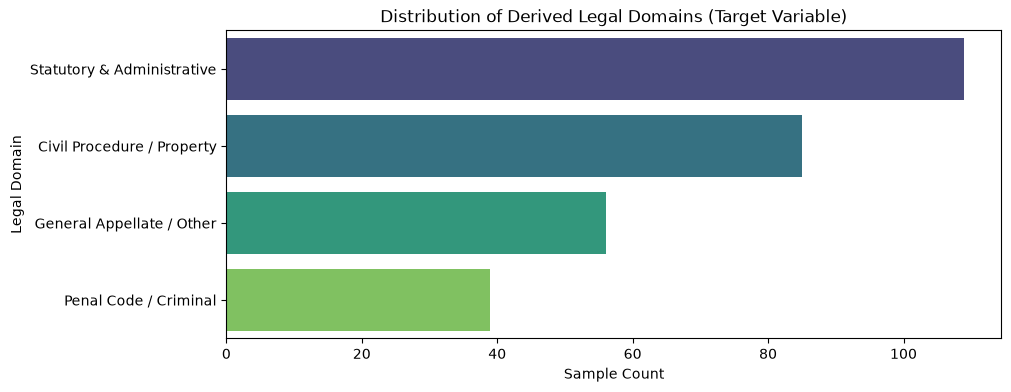

In [5]:
# 1. Dynamically find the correct text field in navodPeiris/sri-lanka-case-law
text_column = 'full_summary' if 'full_summary' in df.columns else 'short_summary'
print(f"Using text column: '{text_column}'")

# 2. Derive Target Variable from structured metadata (laws_referred)
if 'laws_referred' in df.columns:
    df['target_domain'] = df['laws_referred'].apply(extract_primary_statute)
else:
    df['target_domain'] = df[text_column].apply(extract_primary_statute)

# Filter out extremely rare classes to maintain stable Macro F1 training splits
domain_counts = df['target_domain'].value_counts()
valid_domains = domain_counts[domain_counts >= 10].index
df = df[df['target_domain'].isin(valid_domains)].copy()

# 3. Strict Pre-Decision Input Features (Using full_summary to prevent circular leakage)
df['input_text'] = df[text_column].fillna('').astype(str)
df = df[df['input_text'].str.strip() != ''].copy()

# Visualize target distribution
plt.figure(figsize=(10, 4))
sns.countplot(data=df, y='target_domain', order=df['target_domain'].value_counts().index, palette='viridis')
plt.title("Distribution of Derived Legal Domains (Target Variable)")
plt.xlabel("Sample Count")
plt.ylabel("Legal Domain")
plt.show()

In [6]:
# Print available columns to check the exact identifier column name
print(f"Available columns in dataframe: {list(df.columns)}")

# Dynamically select a valid grouping column to prevent leakage as required
group_candidates = ['case_no', 'case_title', 'citation', 'case_name', 'id', 'file_name']
group_col = None

for col in group_candidates:
    if col in df.columns:
        group_col = col
        break

if group_col:
    print(f"Using column '{group_col}' for grouped leakage isolation.")
    df['group_id'] = df[group_col].fillna('unknown_case')
else:
    print("No standard group column found. Creating synthetic group IDs.")
    df['group_id'] = [f"case_{i}" for i in range(len(df))]

# Perform Strict Grouped Shuffle Split
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
train_val_idx, test_idx = next(gss_test.split(df, groups=df['group_id']))

train_val_df = df.iloc[train_val_idx].copy()
test_df = df.iloc[test_idx].copy()

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.1765, random_state=42) # ~15% of total
train_idx, val_idx = next(gss_val.split(train_val_df, groups=train_val_df['group_id']))

train_df = train_val_df.iloc[train_idx].copy()
val_df = train_val_df.iloc[val_idx].copy()

# Export split datasets to local data folder
os.makedirs('data', exist_ok=True)
train_df.to_csv('data/train.csv', index=False)
val_df.to_csv('data/val.csv', index=False)
test_df.to_csv('data/test.csv', index=False)

print("\n--- DATA PREPARATION & LEAKAGE ISOLATION COMPLETE ---")
print(f"Train samples: {len(train_df)} | Validation samples: {len(val_df)} | Test samples: {len(test_df)}")

Available columns in dataframe: ['source', 'case_no', 'court_citation', 'court', 'case_title', 'short_summary', 'full_summary', 'decided_date', 'judges', 'citations', 'laws_referred', 'arguments', 'judgements', 'target_domain', 'input_text']
Using column 'case_no' for grouped leakage isolation.

--- DATA PREPARATION & LEAKAGE ISOLATION COMPLETE ---
Train samples: 201 | Validation samples: 44 | Test samples: 44
